In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from matplotlib.ticker import FuncFormatter

file_path = "經濟部進出口資料.xlsx"  
df = pd.read_excel(file_path)

df.rename(columns={df.columns[0]: "Date"}, inplace=True) 
df["Year"] = df["Date"].str.extract(r'(\d+)年')[0].astype(int) + 1911  
df["Month"] = df["Date"].str.extract(r'(\d+)月')[0].astype(int) 
df["Date"] = pd.to_datetime(df[["Year", "Month"]].assign(day=1)) 
df.drop(columns=["Year", "Month"], inplace=True)

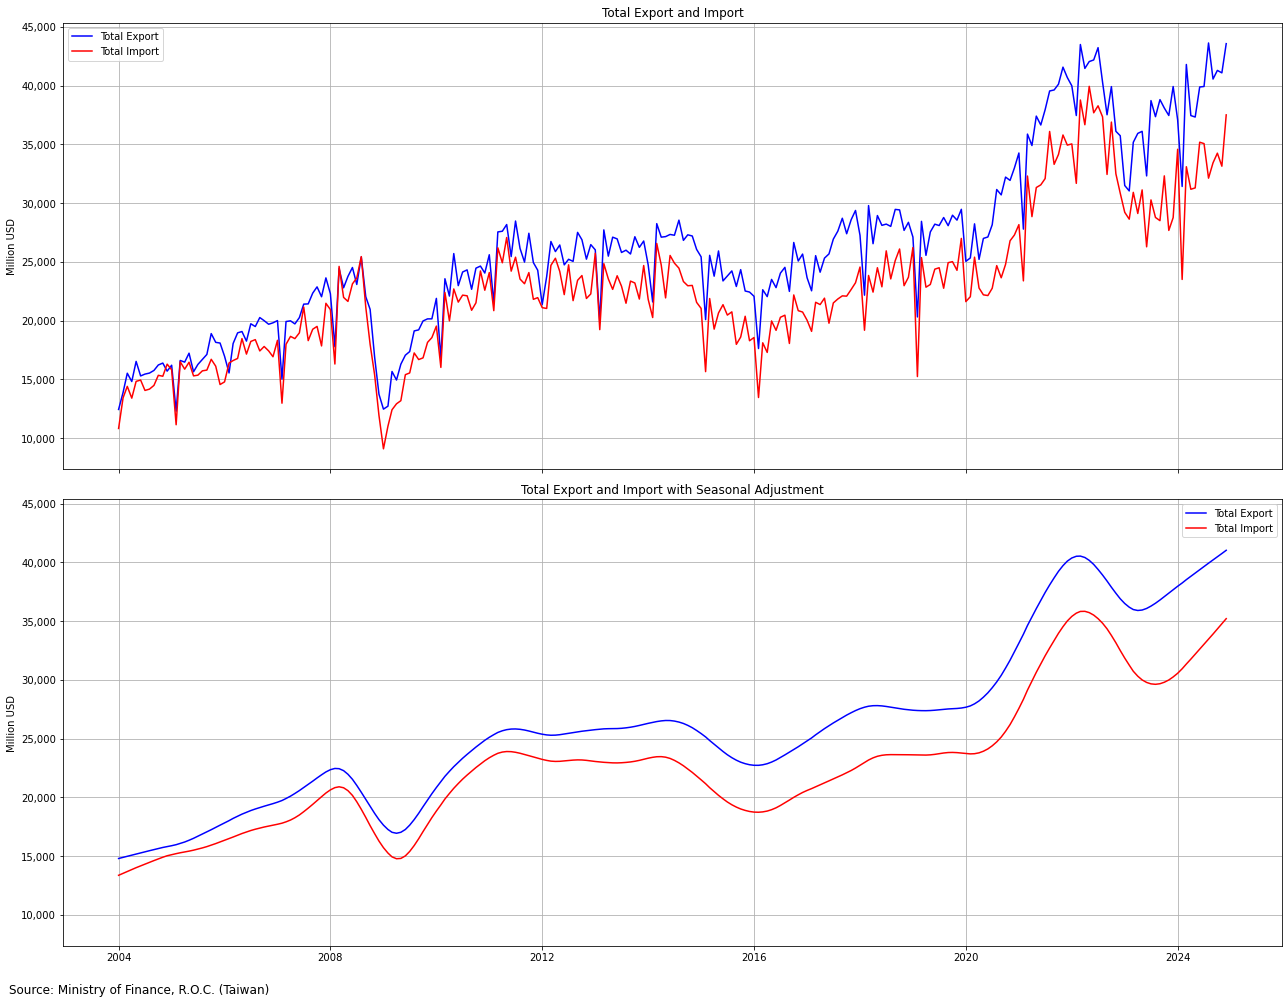

In [7]:
export_ts = pd.Series(df["Total Export"].values, index=df["Date"]).asfreq("MS")
import_ts = pd.Series(df["Total Import"].values, index=df["Date"]).asfreq("MS")

export_trend = STL(export_ts, period=12).fit().trend
import_trend = STL(import_ts, period=12).fit().trend

fig, axes = plt.subplots(2, 1, figsize=(18, 14), sharex=True, sharey=True)

axes[0].plot(df["Date"], df["Total Export"], label="Total Export", color="blue")
axes[0].plot(df["Date"], df["Total Import"], label="Total Import", color="red")
axes[0].set_title("Taiwan Total Export and Import")
axes[0].legend()
axes[0].grid(True)
axes[0].set_ylabel("Million USD")

axes[1].plot(export_trend, label="Total Export", color="blue")
axes[1].plot(import_trend, label="Total Import", color="red")
axes[1].set_title("Taiwan Total Export and Import with Seasonal Adjustment")
axes[1].legend()
axes[1].grid(True)
axes[1].set_ylabel("Million USD")

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")
for ax in axes:
    ax.yaxis.set_major_formatter(formatter)

plt.figtext(0.01, 0.01, "Source: Ministry of Finance, R.O.C. (Taiwan)", ha='left', fontsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

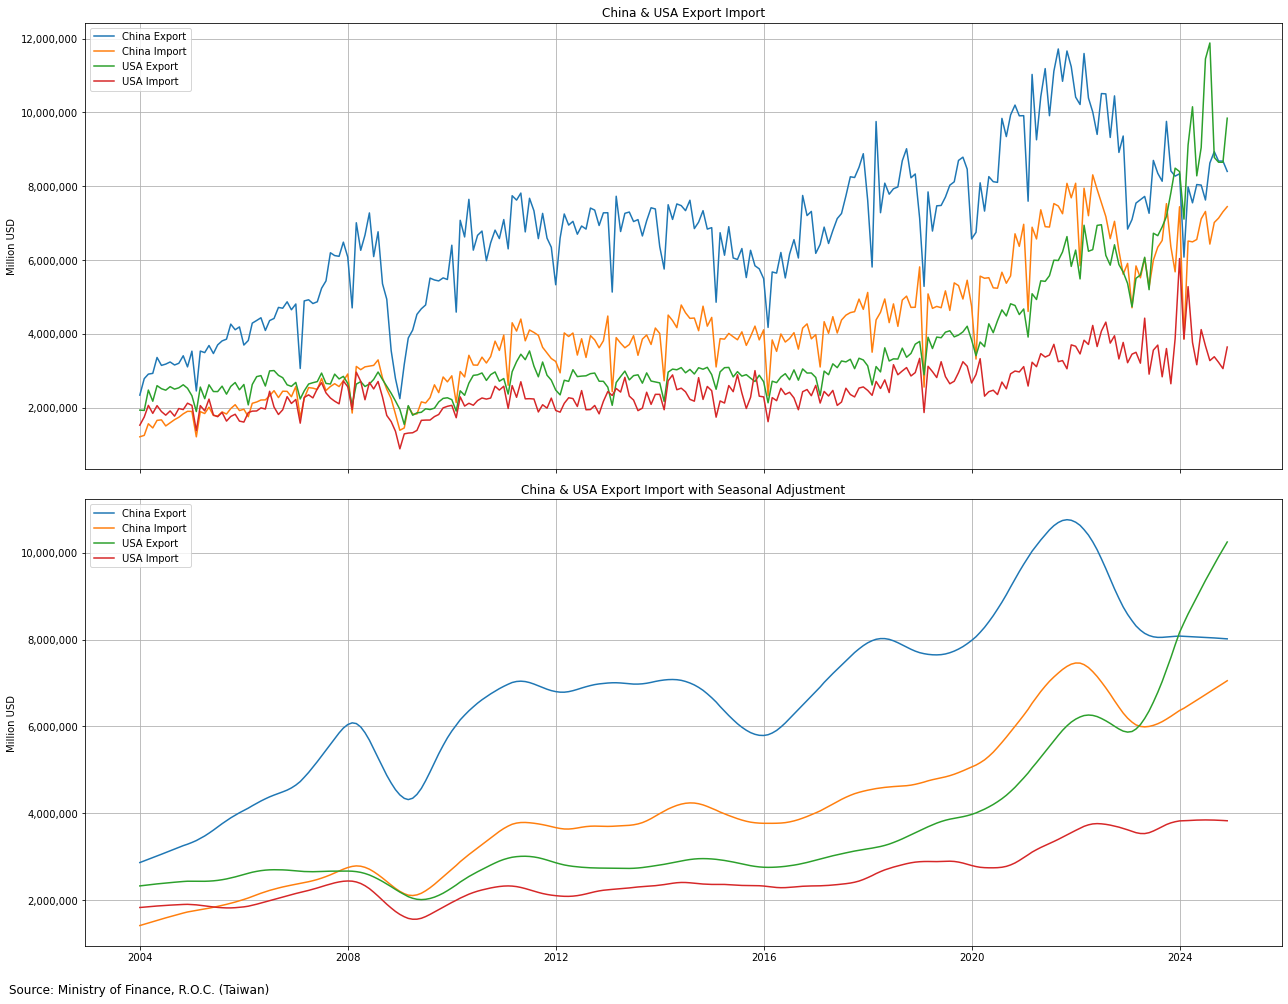

In [8]:
target_cols=["China Export", "China Import", "USA Export", "USA Import"]
df = df[["Date"] + target_cols].copy()
df.columns = ["Date", "China Export", "China Import", "USA Export", "USA Import"]
df.set_index("Date", inplace=True)

stl_result = {}
for col in df.columns:
    ts = df[col].asfreq("MS")
    try:
        trend = STL(ts, period=12).fit().trend
        stl_result[col] = trend
    except Exception as e:
        print(f"跳過：{col}，原因：{e}")

fig, axes = plt.subplots(2, 1, figsize=(18, 14), sharex=True)

for col in df.columns:
    axes[0].plot(df.index, df[col], label=col)
axes[0].set_title("China & USA Export Import")
axes[0].legend()
axes[0].grid(True)
axes[0].set_ylabel("Million USD")

for col, trend in stl_result.items():
    axes[1].plot(trend, label=col)
axes[1].set_title("China & USA Export Import with Seasonal Adjustment")
axes[1].legend()
axes[1].grid(True)
axes[1].set_ylabel("Million USD")

formatter = FuncFormatter(lambda x, _: f"{x:,.0f}")
for ax in axes:
    ax.yaxis.set_major_formatter(formatter)
plt.figtext(0.01, 0.01, "Source: Ministry of Finance, R.O.C. (Taiwan)", ha='left', fontsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()